# Công đoạn 03 — Phân tích khám phá F54
## Mục tiêu và phương pháp
Chỉ EDA trên Train; không chuẩn hóa, chọn đặc trưng hay huấn luyện. Làm sạch như Notebook 01: kiểm tra miền Likert, giữ nguyên câu trả lời văn bản và trim nhãn ngành, không xóa mẫu. Giữ thứ tự q1–q54. Tái lập Notebook 02: nhóm vector tuple, factorize theo thứ tự xuất hiện; StratifiedGroupKFold(5, shuffle=True, random_state=42), fold đầu tiên. Đối chiếu trực tiếp code chia của Notebook 02 qua AST và kiểm tra index bằng nhau. Không chạy phần thống kê Test của Notebook 02.

In [1]:
from pathlib import Path
import sys, ast
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import StratifiedGroupKFold
import nbformat
assert sys.version_info[:2] == (3,14)
ROOT = next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'data_AI_1000_rows.xlsx').is_file())
raw = pd.read_excel(ROOT/'data_AI_1000_rows.xlsx',sheet_name='AUGMENTED_RAW_1000')
metadata = ['Dấu thời gian','Tên Sinh viên','Ngành học','Giới tính']
assert raw.shape == (1000,58) and list(raw.columns[:4]) == metadata
questions = list(raw.columns[4:])
levels = ['Chưa bao giờ đúng','Chỉ đúng 1 vài trường hợp','Chỉ đúng 1 nửa','Gần như là đúng','Hoàn toàn đúng']
X = raw[questions].copy()
y = raw['Ngành học'].astype('string').str.strip()
assert X.notna().all().all() and X.isin(levels).all().all()
assert y.notna().all() and y.ne('').all() and y.nunique() == 33
assert X.shape[1] == 54 and not set(metadata).intersection(X.columns)
groups = pd.Series(pd.factorize(pd.Series(list(X.itertuples(index=False, name=None))), sort=False)[0], index=X.index)
splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
train_pos, test_pos = next(splitter.split(X, y, groups))
ref = nbformat.read(ROOT/'data/ml_pipeline/notebooks/02_chia_du_lieu.ipynb',4)
src = next(c.source for c in ref.cells if c.cell_type=='code' and 'from sklearn.model_selection import StratifiedGroupKFold' in c.source)
nodes = [node for node in ast.parse(src).body if isinstance(node,ast.Assign) and any(
    isinstance(t,ast.Name) and t.id in {'groups','splitter'} or isinstance(t,ast.Tuple) and [v.id for v in t.elts]==['train_pos','test_pos'] for t in node.targets)]
assert len(nodes)==3
check = {'pd':pd,'X':X,'y':y,'StratifiedGroupKFold':StratifiedGroupKFold}
exec(compile(ast.Module(body=nodes,type_ignores=[]),'<Notebook02 split>','exec'),check)
assert groups.equals(check['groups'])
assert np.array_equal(train_pos,check['train_pos']) and np.array_equal(test_pos,check['test_pos'])
X_train,y_train = X.iloc[train_pos].copy(),y.iloc[train_pos].copy()
assert X_train.shape==(800,54) and y_train.nunique()==33
assert len(test_pos)==200 and len(train_pos)+len(test_pos)==len(X)
assert X.index.is_unique and not set(train_pos).intersection(test_pos)
assert set(groups.iloc[train_pos]).isdisjoint(groups.iloc[test_pos])
print('PASS: index đúng Notebook 02; Train 800 x 54, 33 ngành; Test 200; không giao index/vector.')
del raw,X,y,groups,check,test_pos,ref


PASS: index đúng Notebook 02; Train 800 x 54, 33 ngành; Test 200; không giao index/vector.


## 1. Phân bố ngành — Train

Nhiều nhất: ['Công nghệ thông tin']
Ít nhất: ['Sư phạm hóa học', 'Toán học', 'Việt Nam học', 'Sư phạm toán học', 'Tài chính - Ngân hàng', 'Nông học', 'Văn học', 'Quản lý giáo dục']
Khoảng số mẫu: 21 58
Tỷ số lớn nhất/nhỏ nhất: 2.761904761904762


                                    Số mẫu  Tỷ lệ (%)
Ngành học                                            
Công nghệ thông tin                     58       7.25
Giáo dục tiểu học                       37      4.625
Ngôn ngữ anh                            35      4.375
Luật                                    32        4.0
Giáo dục chính trị                      23      2.875
Kỹ thuật phần mềm                       23      2.875
Kế toán                                 23      2.875
Sư phạm ngữ văn                         23      2.875
Công nghệ kỹ thuật xây dựng             23      2.875
Sư phạm địa lý                          23      2.875
Đông phương học                         23      2.875
Kỹ thuật điện tử - viễn thông           23      2.875
Giáo dục mầm non                        22       2.75
Kỹ thuật điện                           22       2.75
Sư phạm tin học                         22       2.75
Tâm lý học giáo dục                     22       2.75
Quản lý nhà nước            

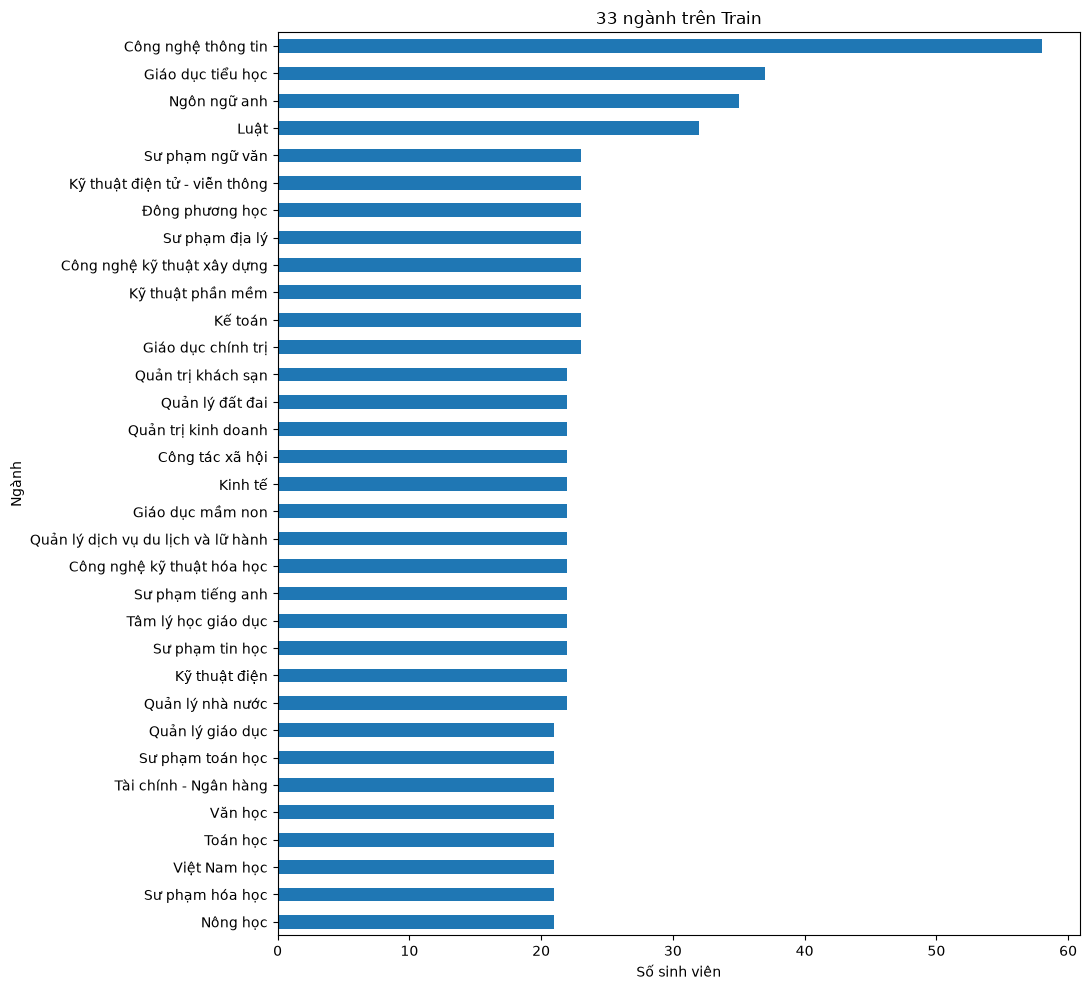

In [2]:
industry = y_train.value_counts().rename('Số mẫu').to_frame()
industry['Tỷ lệ (%)'] = industry['Số mẫu']/len(y_train)*100
display(industry.round(3))
fig,ax = plt.subplots(figsize=(11,10))
industry['Số mẫu'].sort_values().plot.barh(ax=ax)
ax.set(title='33 ngành trên Train',xlabel='Số sinh viên',ylabel='Ngành')
plt.tight_layout(); plt.show()
print('Nhiều nhất:',industry.index[industry['Số mẫu'].eq(industry['Số mẫu'].max())].tolist())
print('Ít nhất:',industry.index[industry['Số mẫu'].eq(industry['Số mẫu'].min())].tolist())
print('Khoảng số mẫu:',industry['Số mẫu'].min(),industry['Số mẫu'].max())
print('Tỷ số lớn nhất/nhỏ nhất:',industry['Số mẫu'].max()/industry['Số mẫu'].min())

Nhận xét: số mẫu và tỷ lệ của toàn bộ 33 ngành được báo cáo ở trên; tỷ số lớn nhất/nhỏ nhất mô tả mất cân bằng. Cỡ mẫu mỗi ngành còn hạn chế cho đánh giá theo lớp; không gộp ngành.

## 2. Phân tích 54 câu
Ánh xạ cố định Likert sang 1–5 chỉ trên Train. Likert là dữ liệu thứ bậc; trung bình và SD chỉ mô tả gần đúng, không chứng minh khoảng cách tâm lý bằng nhau. Ngưỡng mô tả: SD <0,5 là rất thấp; một mức chiếm ≥80% là lệch mạnh. Không xóa câu hỏi.

SD nhỏ nhất/lớn nhất: 0.821046677758837 1.2851223382543586
Biến thiên rất thấp: [] ; lệch mạnh: []


      mean  median    std  min  max  Mức 1 (%)  Mức 2 (%)  Mức 3 (%)  Mức 4 (%)  Mức 5 (%)  Mức phổ biến (%)
q1   3.468     4.0  1.032  1.0  5.0      2.250     17.500     28.000     35.750     16.500            35.750
q2   3.784     4.0  0.981  1.0  5.0      1.375     10.375     21.875     41.250     25.125            41.250
q3   3.660     4.0  1.026  1.0  5.0      1.875     11.500     29.625     32.750     24.250            32.750
q4   2.698     3.0  1.037  1.0  5.0     11.375     34.500     31.875     17.500      4.750            34.500
q5   2.560     2.0  1.165  1.0  5.0     19.125     34.500     25.250     13.500      7.625            34.500
q6   3.910     4.0  1.094  1.0  5.0      2.375     10.125     20.000     29.125     38.375            38.375
q7   2.451     2.0  1.058  1.0  5.0     19.500     35.250     30.500     10.125      4.625            35.250
q8   3.270     3.0  1.145  1.0  5.0      5.875     20.625     31.500     24.625     17.375            31.500
q9   2.820     3.0 

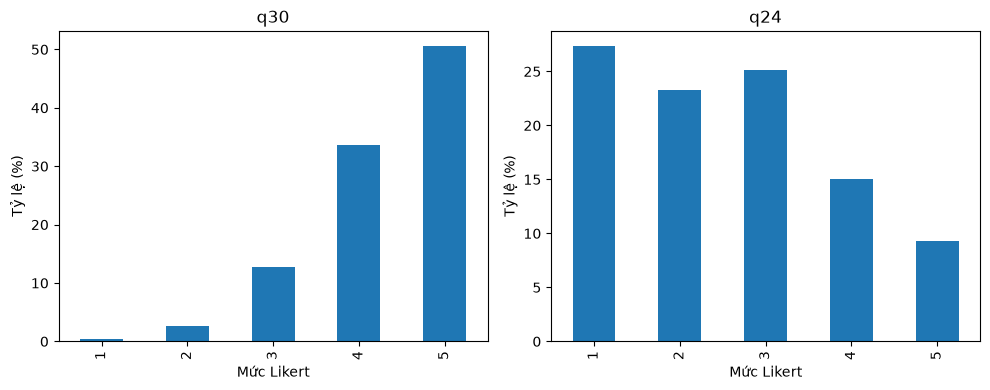

                            Nội dung
q30  30. Tôi là người lịch sự, tử tế
q24    24. Tôi có năng khiếu âm nhạc

In [3]:
A = X_train.apply(lambda s:s.map(dict(zip(levels,range(1,6))))).astype('int64')
A.columns = [f'q{i}' for i in range(1,55)]
assert A.notna().all().all() and A.isin(range(1,6)).all().all()
content = pd.Series(questions,index=A.columns)
stats = A.agg(['mean','median','std','min','max']).T
rates = pd.DataFrame({f'Mức {k} (%)':A.eq(k).mean()*100 for k in range(1,6)})
stats = stats.join(rates)
stats['Mức phổ biến (%)'] = rates.max(axis=1)
low = stats.index[stats['std']<.5].tolist()
skewed = stats.index[stats['Mức phổ biến (%)']>=80].tolist()
display(stats.round(3))
print('SD nhỏ nhất/lớn nhất:',stats['std'].min(),stats['std'].max())
print('Biến thiên rất thấp:',low,'; lệch mạnh:',skewed)
representatives = list(dict.fromkeys([stats['std'].idxmin(),stats['std'].idxmax(),stats['Mức phổ biến (%)'].idxmax()]))
fig,axes = plt.subplots(1,len(representatives),figsize=(5*len(representatives),4),squeeze=False)
for ax,q in zip(axes.flat,representatives):
    A[q].value_counts(normalize=True).reindex(range(1,6),fill_value=0).mul(100).plot.bar(ax=ax)
    ax.set(title=q,xlabel='Mức Likert',ylabel='Tỷ lệ (%)')
plt.tight_layout(); plt.show()
display(content.loc[representatives].rename('Nội dung').to_frame())

Nhận xét: các câu đại diện được chọn theo SD nhỏ nhất, lớn nhất và tỷ lệ mức phổ biến cao nhất, không dùng nhãn ngành. Kết quả ngưỡng được in trên; không tự loại biến.

## 3. Tương quan và đối chiếu nội dung
Dùng Spearman trên Train vì thang thứ bậc. Quy ước cao: |rho| ≥0,8; rất cao: ≥0,9. Tương quan cao không tự chứng minh trùng nội dung hoặc phải loại bỏ. Chưa có danh sách mã câu nghi ngờ trong yêu cầu; rà soát token bổ sung là heuristic, không thay thế codebook/thẩm định ngữ nghĩa.

Cặp cao/rất cao: 0 0
q42 q51 0.5787
42. Tôi thường đặt ra các mục tiêu, kế hoạch trong cuộc sống
51. Tôi thường đặt ra mục tiêu, kế hoạch trong cuộc sống
q44 q45 0.5418
44. Tôi là người thích cạnh tranh, và muốn mình giỏi hơn người khác
45. Tôi muốn người khác phải kính trọng, nể phục tôi
q34 q35 0.5381
34. Tôi thích các hoạt động vì mục tiêu chung của cộng đồng, xã hội
35. Tôi mong muốn mình có thể đóng góp để xã hội tốt đẹp hơn
q22 q40 0.5333
22. Tôi có khả năng thuyết trình, diễn xuất
40. Tôi có khả năng diễn đạt, tranh luận và thuyết phục người khác
q36 q40 0.4838
36. Tôi có khả năng hoà giải, giải quyết những công việc mâu thuẫn
40. Tôi có khả năng diễn đạt, tranh luận và thuyết phục người khác
Gần nội dung: ('q11', 'q18', 0.5454545454545454, np.float64(0.44751434846888566))
11. Tôi có khả năng phân tích vấn đề
18. Tôi có khả năng giải quyết các vấn đề
Gần nội dung: ('q19', 'q39', 0.5714285714285714, np.float64(-0.04567629409471375))
19. Tôi là người dễ xúc động
39. Tôi là người n

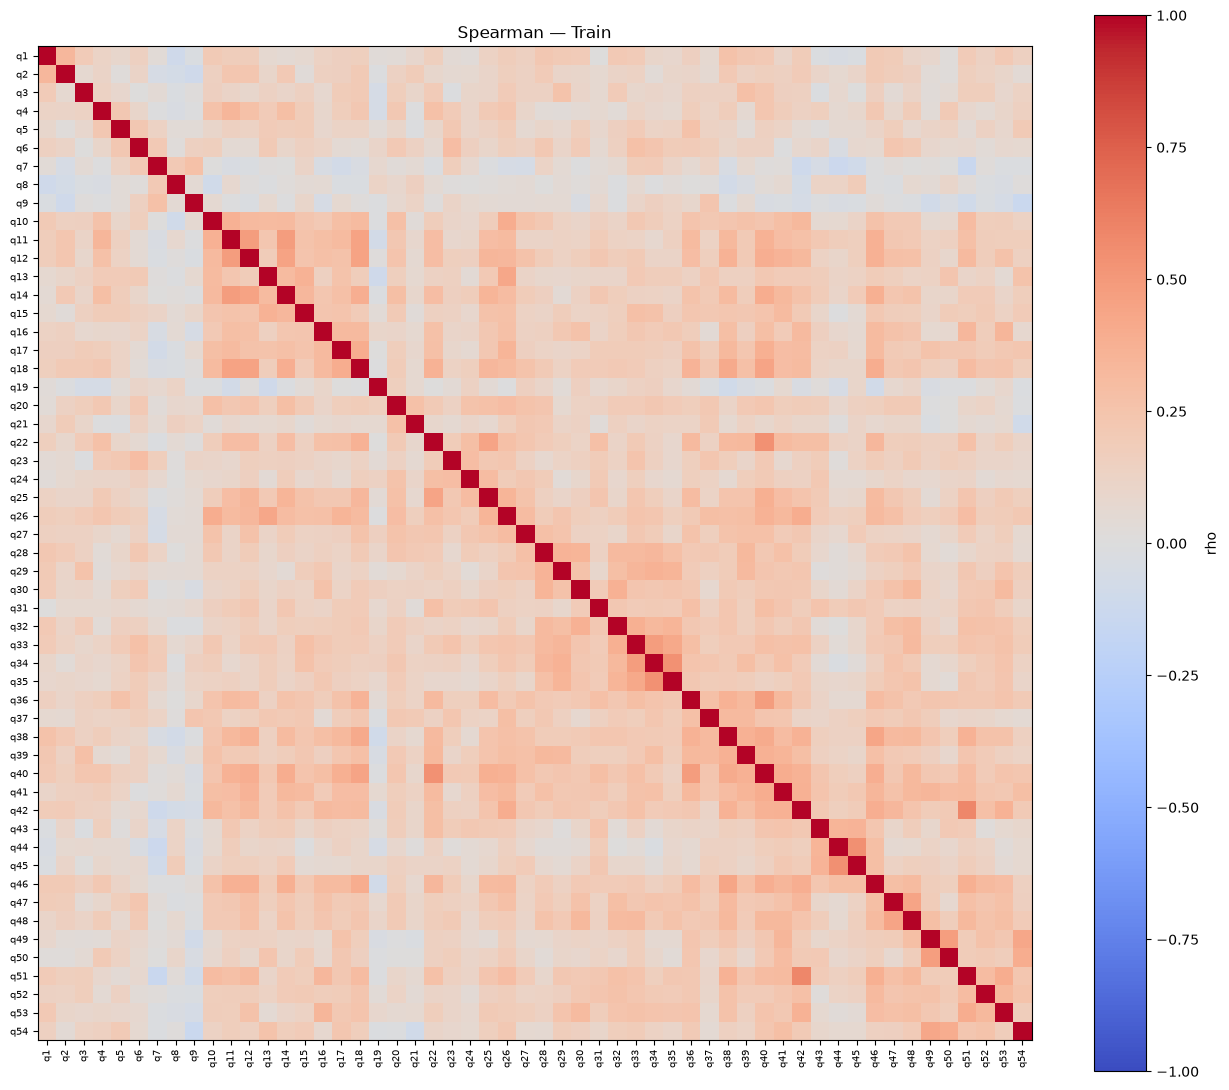

Empty DataFrame
Columns: [Câu 1, Câu 2, rho, |rho|]
Index: []

In [4]:
corr = A.corr(method='spearman')
fig,ax = plt.subplots(figsize=(13,11))
im = ax.imshow(corr,vmin=-1,vmax=1,cmap='coolwarm')
ax.set_xticks(range(54),A.columns,rotation=90,fontsize=7)
ax.set_yticks(range(54),A.columns,fontsize=7)
ax.set_title('Spearman — Train'); fig.colorbar(im,ax=ax,label='rho')
plt.tight_layout(); plt.show()
pairs = pd.DataFrame([(A.columns[i],A.columns[j],corr.iloc[i,j]) for i in range(54) for j in range(i+1,54)],columns=['Câu 1','Câu 2','rho'])
pairs['|rho|'] = pairs['rho'].abs()
pairs = pairs.sort_values('|rho|',ascending=False)
high = pairs[pairs['|rho|']>=.8]
display(high.round(4))
print('Cặp cao/rất cao:',len(high),int((pairs['|rho|']>=.9).sum()))
top = pairs.head(5).copy()
for _,r in top.iterrows():
    print(r['Câu 1'],r['Câu 2'],round(r['rho'],4))
    print(content[r['Câu 1']]); print(content[r['Câu 2']])
import re
words = [set(re.findall(r'[^\W\d_]+',str(s).casefold())) for s in questions]
similar = []
for i in range(54):
    for j in range(i+1,54):
        score = len(words[i]&words[j])/len(words[i]|words[j]) if words[i]|words[j] else 0
        if score>=.5:
            similar.append((A.columns[i],A.columns[j],score,corr.iloc[i,j]))
            print('Gần nội dung:',similar[-1]); print(questions[i]); print(questions[j])
print('Số cặp Jaccard >=0,5:',len(similar))

Nhận xét: không có cặp đạt |rho| ≥0,8. q42 và q51 gần như cùng câu về đặt mục tiêu/kế hoạch, chỉ khác từ “các”, nhưng rho chỉ 0,579; đây là dấu hiệu dư thừa về nội dung cần xem xét riêng ở Notebook 05. q11–q18 cùng nói về vấn đề nhưng phân tích và giải quyết là hai hành vi khác nhau (rho 0,448). q19–q39 có nhiều từ chung nhưng “dễ xúc động” khác “năng động”, rho −0,046; minh họa giới hạn của Jaccard. q34–q35 cùng chủ đề đóng góp cộng đồng nhưng hoạt động và mong muốn không đồng nhất. Không loại hoặc gộp câu nào.

## 4. Liên hệ với ngành
Minh họa trung vị của các câu đại diện trên sáu ngành nhiều mẫu nhất; không chọn đặc trưng bằng bảng này. Không suy luận nhân quả, mức phù hợp nghề nghiệp hoặc nhóm RIASEC.

In [5]:
group_data = A[representatives].copy()
group_data['Ngành'] = y_train
selected = industry.head(6).index
group_summary = group_data.groupby('Ngành')[representatives].median().reindex(selected)
group_summary.insert(0,'Số mẫu',industry.loc[selected,'Số mẫu'])
display(group_summary)
print('Bảng chỉ mô tả trung vị trong mẫu; không kiểm định khác biệt hay xác nhận khả năng dự đoán.')

Bảng chỉ mô tả trung vị trong mẫu; không kiểm định khác biệt hay xác nhận khả năng dự đoán.


                     Số mẫu  q30  q24
Ngành học                            
Công nghệ thông tin      58  5.0  1.0
Giáo dục tiểu học        37  5.0  2.0
Ngôn ngữ anh             35  5.0  3.0
Luật                     32  4.0  2.0
Giáo dục chính trị       23  5.0  2.0
Kỹ thuật phần mềm        23  4.0  2.0

## Kết luận EDA
1. Train có 33 ngành, mỗi ngành 21–58 mẫu; tỷ số lớn nhất/nhỏ nhất 2.76. Không hoàn toàn cân bằng; cỡ mẫu lớp còn nhỏ.
2. SD của 54 câu từ 0.821 đến 1.285; có 0 câu SD <0,5 và 0 câu có một mức ≥80%. Không loại câu nào.
3. Có 0 cặp |rho| ≥0,8, trong đó 0 cặp ≥0,9. Mạnh nhất: q42–q51, rho=0.5787.
4. Không có tương quan cao theo ngưỡng. Riêng q42–q51 gần như trùng nội dung, cần xem xét dư thừa ở Notebook 05 cùng nội dung và codebook; chưa đủ bằng chứng loại/gộp.
5. 54 biến thứ bậc, 33 lớp và 800 mẫu Train yêu cầu cân nhắc giả định khoảng cách Likert, tương quan và đánh giá theo lớp. Chưa thể khẳng định độ chính xác trước huấn luyện.
6. Nhãn ngành đang học không phải nhãn phù hợp nghề nghiệp. Thiếu codebook RIASEC và xác thực ngoài mẫu; chưa thể khẳng định dự đoán ngành phù hợp theo Holland.

## Kiểm chứng
5/5 cell chạy tuần tự bằng tiến trình Python 3.14 mới. Hình nhúng trực tiếp, không xuất file phụ. Dùng phương án chạy Python theo giới hạn quyền Jupyter đã ghi nhận ở Notebook 02; chưa kiểm chứng bằng kernel Jupyter. Test chỉ dùng kiểm tra phép chia; mọi thống kê và hình EDA chỉ dùng Train. Không fit scaler/PCA, chọn đặc trưng hoặc huấn luyện. Dừng ở Notebook 03.
